# 유의성 부풀리기 의도적 오용 시연

**PRELIMINARY · INTENTIONAL_MISUSE · 본 연구 검증 결과로 사용 금지**

실제 관측값을 수정하거나 매출을 합성하지 않는다. 사전에 고정한 중심점 500m·파싱 후보 ID 가용률 100%의 5,015행으로, ① 군집 무시와 고정효과 제거, ② 동일 행을 독립 정보처럼 반복, ③ 결과를 이용한 행 제외가 추정치와 겉보기 유의성에 미치는 영향을 공개한다. 모든 시도를 기록하며 더 작은 p값을 얻기 위한 반복 탐색은 하지 않는다. 분기 자료는 일별 매출이나 공연 직후 소비가 아니다. 예정 시작회차는 실제 공연 개최·관객 수가 아니다.

A의 고정효과 제거는 지역 간 차이를 포함하는 **다른 기술적 추정 대상**이다. B의 iid 추론과 C의 결과 선택 후 추론은 **의도적 오용**이다. 이들은 연구 개선안이나 인과효과가 아니다. 기준 상권 군집 추론도 연구 설계의 조건부 연관성에 대한 것으로 인과 검증은 아니다.

실험 C는 결과 확인 전에 **커피·음료(CS100010)의 총매출액**으로 고정했다. 원표본에서 한 번 계산한 잔차 x×잔차 y 기여를 오름차순 정렬하여 0/1/2/5/10/20%를 제외한다. 선택 방향은 양의 기울기를 유도하는 방향이고, 보고하는 p값은 양측 검정의 계산값이지만 **선택 후 유효한 p값이 아니다**.

In [1]:
from pathlib import Path
import os
for name in ['OPENBLAS_NUM_THREADS','MKL_NUM_THREADS','OMP_NUM_THREADS']: os.environ[name]='1'
import ast,json,hashlib,platform
from datetime import datetime,timezone
import numpy as np
import pandas as pd
from scipy import linalg,stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display,Markdown
ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'test/metadata/lab_plan.json').is_file())
OUT=ROOT/'test/reports'; OUT.mkdir(parents=True,exist_ok=True)
sha=lambda p:hashlib.sha256(p.read_bytes()).hexdigest()
read_json=lambda p:json.loads(p.read_text(encoding='utf-8'))
LAB_PATH=ROOT/'test/metadata/lab_plan.json'; LAB=read_json(LAB_PATH)
PROTECTED=dict(LAB['protected_sha256']); PROTECTED[LAB_PATH.relative_to(ROOT).as_posix()]=sha(LAB_PATH)
assert LAB['exploratory'] and not LAB['confirmatory'] and not LAB['raw_data_mutated']
assert all(sha(ROOT/p)==h for p,h in PROTECTED.items()),'Protected input differs before experiment'
PLAN=read_json(ROOT/'final/metadata/revised_quarterly_plan.json')
KEY=['area_id','industry_id','quarter']; INDUSTRY_IDS=[f'CS100{i:03d}' for i in range(1,11)]
OUTCOMES={'log1p_total_sales_won':'total_sales','log1p_night_sales_21_24_won':'night_sales'}
TRIM_INDUSTRY='CS100010'; TRIM_OUTCOME='log1p_total_sales_won'
REPLICATION_FACTORS=[1,5,20,100,1000]; TRIM_FRACTIONS=[0,.01,.02,.05,.10,.20]
pd.set_option('display.max_rows',30)
print('고정 입력',len(PROTECTED),'개 / 결과 선택 대상',TRIM_INDUSTRY,TRIM_OUTCOME)


고정 입력 306 개 / 결과 선택 대상 CS100010 log1p_total_sales_won


## 고정 입력과 기준 모형

13번 수정 분석의 결과변수별 표본 키를 그대로 대조한다. 총매출과 야간 매출의 표본은 동일하며 원매출 결측은 0으로 대체하지 않는다. 기존 노트북에서 함수 정의만 읽어 실행하며 기존 노트북의 파일 저장·모형 실행 셀은 실행하지 않는다. 최소 2분기·업종별 20상권 조건을 유지한다.

In [2]:
panel=pd.read_csv(ROOT/'data/analysis/final/revised_quarterly/revised_quarterly_panel.csv',dtype={k:str for k in KEY})
member=pd.read_csv(ROOT/'reports/final/revised_quarterly/13_sample_membership.csv',dtype={k:str for k in KEY})
reference=pd.read_csv(ROOT/'reports/final/revised_quarterly/13_effects.csv',dtype={'industry_id':str})
keys=member.loc[member.scenario.eq('primary_centroid100') & member.outcome.eq(TRIM_OUTCOME),KEY]
keys_night=member.loc[member.scenario.eq('primary_centroid100') & member.outcome.eq('log1p_night_sales_21_24_won'),KEY]
assert keys.sort_values(KEY).reset_index(drop=True).equals(keys_night.sort_values(KEY).reset_index(drop=True))
assert len(keys)==5015 and not keys.duplicated(KEY).any()
frame=keys.merge(panel,on=KEY,how='left',validate='one_to_one').sort_values(KEY).reset_index(drop=True)
assert frame.total_sales.notna().all() and frame.night_sales.notna().all()
assert frame.total_sales.gt(0).all() and frame.night_sales.ge(0).all()
assert frame.groupby(['area_id','industry_id']).quarter.nunique().min()>=2
assert frame.groupby('industry_id').area_id.nunique().min()>=20
frame['x']=np.log1p(frame.known_scheduled_start_count_centroid500)
for outcome,raw in OUTCOMES.items(): frame[outcome]=np.log1p(frame[raw])
INDUSTRY_NAMES=frame.drop_duplicates('industry_id').set_index('industry_id').industry.to_dict()
key_hash=lambda f:hashlib.sha256(f[KEY].sort_values(KEY).to_csv(index=False,lineterminator='\n').encode('utf-8')).hexdigest()
SAMPLE_HASH=key_hash(frame)
def load_function(path,name):
    found=[]
    for cell in read_json(path)['cells']:
        if cell['cell_type']!='code': continue
        source=''.join(cell['source'])
        if any(line.lstrip().startswith(('%','!')) for line in source.splitlines()): continue
        found.extend(z for z in ast.parse(source).body if isinstance(z,ast.FunctionDef) and z.name==name)
    assert len(found)==1,(path,name)
    exec(compile(ast.fix_missing_locations(ast.Module(body=found,type_ignores=[])),str(path),'exec'),globals())
load_function(ROOT/'final/notebooks/05_외식업_고정효과분석.ipynb','absorb_effects')
load_function(ROOT/'final/notebooks/13_분기매출액_수정분석.ipynb','fit_system')
models={outcome:fit_system(frame,outcome) for outcome in OUTCOMES}
checks=[]
for outcome,m in models.items():
    ref=reference.loc[reference.scenario.eq('primary_centroid100') & reference.outcome.eq(outcome)].set_index('industry_id')
    for j,b in enumerate(m['blocks']):
        r=ref.loc[b['industry_id']]; se=float(np.sqrt(m['cov'][j,j])); p=float(2*stats.t.sf(abs(m['beta'][j]/se),m['df']))
        error=max(abs(m['beta'][j]-r.coefficient),abs(se-r.standard_error),abs(p-r.p_value))
        assert error<1e-10
        checks.append(dict(check='baseline13_reproduction',outcome=outcome,industry_id=b['industry_id'],passed=True,max_abs_error=error))
print('기준 재현 완료:',len(frame),'행,',frame.area_id.nunique(),'상권, 표본 SHA256:',SAMPLE_HASH)
display(frame.groupby('industry').agg(rows=('quarter','size'),clusters=('area_id','nunique')))


기준 재현 완료: 5015 행, 114 상권, 표본 SHA256: aee94fa1c4f1c835e7695643fa4490d73a7a76d397ad195fb84957e3104282fb


,rows,clusters
industry,,
분식전문점,575,64
양식음식점,412,50
일식음식점,282,35
제과점,330,40
중식음식점,292,37
치킨전문점,309,37
커피-음료,882,97
패스트푸드점,263,33
한식음식점,1021,106


## 계산 정의와 p값 표시

기준 TWFE는 상권×업종 및 업종×분기 고정효과, 업종별 기울기, 상권 군집 CR1 공분산을 사용한다. 기준 모형의 t 자유도는 공동 모형 전체 상권 수−1이다. iid 비교는 같은 공동 OLS의 동분산 잔차분산 RSS/(N−K)를 사용한다. 따라서 독립성뿐 아니라 동분산도 가정한다.

β의 단위는 ln(1+예정 시작회차)가 1 증가할 때 ln(1+매출 원)이 달라지는 양이다. 1+노출 2배의 변환은 100×{exp(β ln2)−1}로, **매출 원+1의 조건부 기하평균 비율**에 관한 값이다. 산술평균 매출 증가율이나 인과효과가 아니다. 야간의 실제 0↔양수 변화도 포함한다. CI는 각 표의 계산 방식에 따른 명목 95% 구간이며, 오용 모형에서는 유효한 추론 구간으로 해석하지 않는다.

모든 p값은 양측이다. 1e−300보다 작으면 숫자 열에 1e−300을 저장하고 `p_is_numeric_floor=True`, 표시 열에는 `<1e-300`을 남긴다. 이는 0의 확률이 아니다. `log10_p`는 가능한 범위에서 로그 확률을 보존한다. 다중 보정은 본 실험의 무효한 추론을 복구하지 않으며 연구 결론용 q값을 만들지 않는다.

In [3]:
from scipy.integrate import quad

def stable_t_logsf(z,df):
    value=float(stats.t.logsf(z,df))
    if np.isfinite(value): return value,'scipy_t_logsf'
    # Scale the tail integral by its density at the lower bound to avoid underflow.
    scale=1/max(float(z),1.); base=float(stats.t.logpdf(z,df))
    integral,error=quad(lambda w:np.exp(stats.t.logpdf(z+w*scale,df)-base),0,np.inf,epsabs=1e-12,epsrel=1e-12)
    assert integral>0 and error<1e-8
    return base+np.log(scale)+np.log(integral),'scaled_tail_quadrature'

def inference(beta,se,distribution,df=None):
    assert np.isfinite(beta) and np.isfinite(se) and se>0
    z=abs(beta/se)
    tail,log_method=stable_t_logsf(z,df) if distribution=='t' else (float(stats.norm.logsf(z)),'scipy_normal_logsf')
    logp=float(np.log(2)+tail)
    logp=min(0.,logp); floor=logp<np.log(1e-300)
    p=1e-300 if floor else float(np.exp(logp))
    crit=stats.t.ppf(.975,df) if distribution=='t' else stats.norm.ppf(.975)
    low,high=beta-crit*se,beta+crit*se
    return dict(coefficient=float(beta),standard_error=float(se),ci_low=float(low),ci_high=float(high),
                statistic=float(beta/se),p_value=p,p_display='<1e-300' if floor else f'{p:.8g}',p_is_numeric_floor=bool(floor),
                log10_p=float(logp/np.log(10)),p_log_computation=log_method,nominal_p_lt_05=bool(logp<np.log(.05)),distribution=distribution,
                inference_df=float(df) if df is not None else None,ci_level=.95,p_sidedness='two-sided',
                doubling_pct=float(100*np.expm1(beta*np.log(2))),doubling_ci_low=float(100*np.expm1(low*np.log(2))),
                doubling_ci_high=float(100*np.expm1(high*np.log(2))))
rows=[]
def record(m,j,outcome,experiment,model,covariance,se,distribution,df,label,validity,replication_factor=1,**extra):
    b=m['blocks'][j]; ind=b['industry_id']
    row=dict(experiment=experiment,experiment_label=label,model=model,covariance=covariance,statistical_validity=validity,
             status='estimated',outcome=outcome,industry_id=ind,industry=INDUSTRY_NAMES[ind],
             unique_rows_total=m['nobs'],nominal_rows_total=m['nobs']*replication_factor,
             unique_rows_industry=len(b['frame']),nominal_rows_industry=len(b['frame'])*replication_factor,
             clusters_total=m['clusters'],clusters_industry=b['frame'].area_id.nunique(),cluster_id='original_area_id',
             model_rank=m['rank'],replication_factor=replication_factor,sample_key_sha256=key_hash(b['frame']),
             coefficient_unit='log1p(sales_won) / log1p(scheduled_start_count)',
             doubling_unit='relative percent difference in conditional geometric mean of sales_won+1; not arithmetic sales growth',
             causal_interpretation_allowed=False,selection_direction='none',selection_used_outcome=False,trim_fraction=0.)
    row.update(inference(float(m['beta'][j]),float(se),distribution,df)); row.update(extra); rows.append(row)

def fit_alternative(source,outcome,effects):
    blocks=[]
    for ind in INDUSTRY_IDS:
        f=source.loc[source.industry_id.eq(ind)].sort_values(KEY).reset_index(drop=True)
        assert f.area_id.nunique()>=20
        z=f[[outcome,'x']].astype(float)
        if effects=='quarter': z=z-z.groupby(f.quarter).transform('mean'); rank=f.quarter.nunique()
        else: z=z-z.mean(); rank=1
        y,x=z.to_numpy().T; info=float(x@x)
        assert info>1e-10
        blocks.append(dict(industry_id=ind,frame=f,y=y,x=x,rank=rank,info=info))
    areas=sorted(source.area_id.unique()); amap={a:i for i,a in enumerate(areas)}
    g=len(areas); n=sum(len(b['x']) for b in blocks); k=sum(b['rank']+1 for b in blocks)
    beta=np.array([b['x']@b['y']/b['info'] for b in blocks]); bread=np.diag([1/b['info'] for b in blocks]); scores=np.zeros((g,len(blocks)))
    for j,b in enumerate(blocks):
        b['residual']=b['y']-beta[j]*b['x']
        np.add.at(scores[:,j],b['frame'].area_id.map(amap).to_numpy(),b['x']*b['residual'])
    correction=g/(g-1)*(n-1)/(n-k); cov=correction*bread@(scores.T@scores)@bread
    return dict(status='estimated',blocks=blocks,beta=beta,cov=cov,bread=bread,scores=scores,area_ids=areas,nobs=n,clusters=g,rank=k,df=g-1,correction=correction)


## A. 같은 관측행에서 추론 가정과 추정 대상을 바꾸기

4개 사양×10업종×2결과를 모두 공개한다. TWFE iid는 군집·이분산을 무시한 시연이다. 분기 FE만 남기는 모형과 상수항만 남기는 모형은 상권 군집 표준오차를 유지하지만 지역 간 매출·공연 밀집의 차이까지 포함한다. 기준과 계수 또는 p값이 달라도 기존 연구 질문에 대한 개선을 뜻하지 않는다.

In [4]:
alternative_models={}
for outcome,m in models.items():
    rss=sum(float(b['residual']@b['residual']) for b in m['blocks'])
    for j,b in enumerate(m['blocks']):
        record(m,j,outcome,'A','TWFE_cluster','area_cluster_CR1',np.sqrt(m['cov'][j,j]),'t',m['df'],
               'INTENTIONAL_MISUSE','REFERENCE_DESIGN_NOT_CAUSAL',method_role='reference',cr1_correction=m['correction'])
        record(m,j,outcome,'A','TWFE_iid','homoskedastic_iid',np.sqrt(rss/(m['nobs']-m['rank'])/b['info']),'t',m['nobs']-m['rank'],
               'INTENTIONAL_MISUSE','INVALID_IF_AREA_DEPENDENCE_OR_HETEROSKEDASTICITY',method_role='ignore_clustering_and_heteroskedasticity')
    for effects,name in [('quarter','quarterFE_cluster'),('intercept','pooled_cluster')]:
        alt=fit_alternative(frame,outcome,effects); alternative_models[(outcome,effects)]=alt
        for j,b in enumerate(alt['blocks']):
            record(alt,j,outcome,'A',name,'area_cluster_CR1',np.sqrt(alt['cov'][j,j]),'t',alt['df'],
                   'DESCRIPTIVE_DIFFERENT_ESTIMAND','CONDITIONAL_CLUSTER_INFERENCE_FOR_DIFFERENT_DESCRIPTIVE_TARGET',
                   method_role='includes_between_area_differences',cr1_correction=alt['correction'])
a_table=pd.DataFrame(rows)
display(a_table.groupby(['model','outcome']).agg(results=('p_value','size'),nominal_below_05=('nominal_p_lt_05','sum'),minimum_p=('p_value','min')))


results  nominal_below_05  \
model             outcome                                                  
TWFE_cluster      log1p_night_sales_21_24_won       10                 0   
                  log1p_total_sales_won             10                 0   
TWFE_iid          log1p_night_sales_21_24_won       10                 0   
                  log1p_total_sales_won             10                 2   
pooled_cluster    log1p_night_sales_21_24_won       10                 4   
                  log1p_total_sales_won             10                 5   
quarterFE_cluster log1p_night_sales_21_24_won       10                 4   
                  log1p_total_sales_won             10                 5   

                                               minimum_p  
model             outcome                                 
TWFE_cluster      log1p_night_sales_21_24_won   0.194232  
                  log1p_total_sales_won         0.130822  
TWFE_iid          log1p_night_sales_21_24_won   0.255958  
                  log1p_total_sales_won         0.007219  
pooled_cluster    log1p_night_sales_21_24_won   0.007590  
                  log1p_total_sales_won         0.001169  
quarterFE_cluster log1p_night_sales_21_24_won   0.005714  
                  log1p_total_sales_won         0.001275

## B. 복사된 행은 새 관측 정보가 아니다

동일 행을 r번 반복하되 원상권 ID를 유지한다고 가정한다. 실제 대용량 복제는 하지 않는다. 기울기는 같고 Nᵣ=rN, RSSᵣ=rRSS, X′Xᵣ=rX′X이므로 iid 기울기 분산은 RSS/{(rN−K)×Sxx}가 된다. 원상권을 군집으로 유지하면 군집 score가 r배, bread가 1/r배여서 **CR1 적용 전 공분산은 그대로**다. CR1ᵣ=G/(G−1)×(rN−1)/(rN−K)만 달라져 보정 후 SE가 완전히 같지는 않다.

작은 실제자료 부분표본을 물리적으로 5번 복사하여 수식과 대조한다. 두 경우 모두 원상권 ID를 유지한다. 복사본에 새 상권 ID를 붙여 독립 관측으로 취급하는 것은 별도의 추가 오용이며 여기서는 하지 않는다.

In [5]:
for outcome,m in models.items():
    rss=sum(float(b['residual']@b['residual']) for b in m['blocks'])
    for r in REPLICATION_FACTORS:
        nr=r*m['nobs']; kr=m['rank']; g=m['clusters']
        correction=g/(g-1)*(nr-1)/(nr-kr)
        for j,b in enumerate(m['blocks']):
            record(m,j,outcome,'B','replicated_TWFE_iid','homoskedastic_iid',np.sqrt(rss/((nr-kr)*b['info'])),'t',nr-kr,
                   'INTENTIONAL_MISUSE','INVALID_PSEUDOREPLICATION_NO_NEW_INFORMATION',replication_factor=r,
                   method_role='copies_falsely_treated_as_independent',cr1_correction=None)
            record(m,j,outcome,'B','replicated_TWFE_original_cluster','area_cluster_CR1',
                   np.sqrt(m['cov'][j,j]*correction/m['correction']),'t',g-1,
                   'INTENTIONAL_MISUSE','REFERENCE_CLUSTER_SAME_INFORMATION_CR1_CHANGES',replication_factor=r,
                   method_role='original_cluster_id_retained',cr1_correction=correction)
small=frame.loc[frame.industry_id.eq(TRIM_INDUSTRY)].copy()
small=small.loc[small.area_id.isin(sorted(small.area_id.unique())[:24])].copy()
physical=pd.concat([small]*5,ignore_index=True)
sm=fit_system(small,TRIM_OUTCOME); pm=fit_system(physical,TRIM_OUTCOME)
r=5; rss=sum(b['residual']@b['residual'] for b in sm['blocks']); prss=sum(b['residual']@b['residual'] for b in pm['blocks'])
variance_formula=np.array([rss/((r*sm['nobs']-sm['rank'])*b['info']) for b in sm['blocks']])
variance_physical=np.array([prss/(pm['nobs']-pm['rank'])/b['info'] for b in pm['blocks']])
cluster_formula=sm['cov']*(sm['clusters']/(sm['clusters']-1)*(r*sm['nobs']-1)/(r*sm['nobs']-sm['rank']))/sm['correction']
errors=dict(beta=float(np.max(abs(sm['beta']-pm['beta']))),iid_variance=float(np.max(abs(variance_formula-variance_physical))),
            cluster_covariance=float(np.max(abs(cluster_formula-pm['cov']))))
assert max(errors.values())<1e-10 and pm['clusters']==sm['clusters'] and pm['rank']==sm['rank']
checks.append(dict(check='small_physical_duplicate_vs_algebra',passed=True,max_abs_error=max(errors.values()),details=json.dumps(errors),original_rows=len(small),physical_rows=len(physical)))
b_table=pd.DataFrame(rows).query("experiment=='B'")
display(b_table.groupby(['model','replication_factor']).agg(results=('p_value','size'),nominal_below_05=('nominal_p_lt_05','sum'),minimum_p=('p_value','min')))
print('물리 복제 대조:',errors)


results  \
model                            replication_factor            
replicated_TWFE_iid              1                        20   
                                 5                        20   
                                 20                       20   
                                 100                      20   
                                 1000                     20   
replicated_TWFE_original_cluster 1                        20   
                                 5                        20   
                                 20                       20   
                                 100                      20   
                                 1000                     20   

                                                     nominal_below_05  \
model                            replication_factor                     
replicated_TWFE_iid              1                                  2   
                                 5                                  5   
                                 20                                 8   
                                 100                               14   
                                 1000                              18   
replicated_TWFE_original_cluster 1                                  0   
                                 5                                  0   
                                 20                                 0   
                                 100                                0   
                                 1000                               0   

                                                         minimum_p  
model                            replication_factor                 
replicated_TWFE_iid              1                    7.218998e-03  
                                 5                    1.776607e-10  
                                 20                   4.878835e-38  
                                 100                 8.629782e-184  
                                 1000                1.000000e-300  
replicated_TWFE_original_cluster 1                    1.308222e-01  
                                 5                    1.088831e-01  
                                 20                   1.052457e-01  
                                 100                  1.042987e-01  
                                 1000                 1.040870e-01

물리 복제 대조: {'beta': 3.122502256758253e-17, 'iid_variance': 2.710505431213761e-20, 'cluster_covariance': 4.336808689942018e-19}


## C. 결과를 본 뒤 행을 지우면 p값의 통상 해석이 무너진다

**선택 후 naive 정규 p값·CI: 검증 추론으로 사용 금지.** 선택과 검정에 같은 y를 사용한다. 커피 총매출의 원표본 TWFE 잔차 x×y를 단 한 번 정렬하고 가장 낮은 기여부터 floor(제외율×원행수)행을 제거한다. 고정 순위는 양의 기울기를 유도하는 한 방향이며, 검정 계산은 양측이다. 각 제거 단계에서 FE를 다시 계산한다. 최소 2분기/상권 조건을 만족하지 못하는 상권은 추가 제외하고 그 행수를 별도로 기록한다. 최소 20상권이나 잔차 x 변동 조건을 위반하면 미추정으로 남긴다. 유의성이 나오도록 임계값을 완화하지 않는다.

이 방법은 관측값의 숫자를 바꾸지 않아도 결과에 의존한 표본 선택으로 추정 대상을 왜곡한다. 제외가 정당한 오류 정정이라는 근거는 없으며, 같은 자료에서 선택한 뒤 계산한 CI와 p값은 선택 불확실성을 반영하지 않는다. 0% 단계도 커피 단일 업종의 iid 정규 근사 기준이므로 A의 공동 모형 군집 SE와는 다르다.

In [6]:
coffee=frame.loc[frame.industry_id.eq(TRIM_INDUSTRY)].sort_values(KEY).reset_index(drop=True).copy()
original_z,original_rank=absorb_effects(coffee,[TRIM_OUTCOME,'x'])
coffee['original_residual_y']=original_z[:,0]; coffee['original_residual_x']=original_z[:,1]
coffee['original_xy_contribution']=original_z[:,0]*original_z[:,1]
ordered=coffee.sort_values(['original_xy_contribution',*KEY],kind='stable').index
coffee['selection_rank']=pd.Series(np.arange(1,len(coffee)+1),index=ordered).reindex(coffee.index).to_numpy()
selection_logs=[]
for fraction in TRIM_FRACTIONS:
    remove_n=int(np.floor(fraction*len(coffee)))
    selected=coffee.selection_rank.le(remove_n)
    candidate=coffee.loc[~selected].copy()
    eligible=candidate.groupby('area_id').quarter.transform('nunique').ge(2)
    kept=candidate.loc[eligible].sort_values(KEY).reset_index(drop=True)
    extra_keys=set(map(tuple,candidate.loc[~eligible,KEY].to_numpy()))
    extra=coffee[KEY].apply(tuple,axis=1).isin(extra_keys)
    log=coffee[KEY+['original_residual_x','original_residual_y','original_xy_contribution','selection_rank']].copy()
    log['trim_fraction']=fraction; log['removed_by_outcome_selection']=selected; log['removed_by_two_quarter_rule']=extra
    log['retained']=~(selected|extra); selection_logs.append(log)
    detail=dict(trim_fraction=fraction,selection_direction='remove_lowest_original_residual_x_times_y_to_favor_positive_slope',
                selection_used_outcome=True,selection_sort='one_fixed_original_sample_order_not_recomputed',
                selection_target_outcome=TRIM_OUTCOME,original_rows_industry=len(coffee),
                rows_removed_by_selection=int(selected.sum()),rows_removed_by_two_quarter_rule=int(extra.sum()),
                rows_removed_total=int(selected.sum()+extra.sum()),
                negative_contribution_rows_removed=int((selected & coffee.original_xy_contribution.lt(0)).sum()),
                positive_contribution_rows_removed=int((selected & coffee.original_xy_contribution.gt(0)).sum()),
                selection_cutoff=float(coffee.loc[selected,'original_xy_contribution'].max()) if remove_n else None)
    g=kept.area_id.nunique()
    if g<20:
        rows.append(dict(experiment='C',experiment_label='INTENTIONAL_MISUSE',model='outcome_selected_TWFE_iid_normal',
                         status='too_few_clusters',statistical_validity='INVALID_POST_SELECTION',outcome=TRIM_OUTCOME,
                         industry_id=TRIM_INDUSTRY,industry=INDUSTRY_NAMES[TRIM_INDUSTRY],unique_rows_total=len(kept),clusters_total=g,**detail))
        continue
    z,rank=absorb_effects(kept,[TRIM_OUTCOME,'x']); y,x=z[:,0],z[:,1]; info=float(x@x)
    if info<=1e-10 or np.std(x)<=1e-10:
        rows.append(dict(experiment='C',experiment_label='INTENTIONAL_MISUSE',model='outcome_selected_TWFE_iid_normal',
                         status='no_identifiable_within_change',statistical_validity='INVALID_POST_SELECTION',outcome=TRIM_OUTCOME,
                         industry_id=TRIM_INDUSTRY,industry=INDUSTRY_NAMES[TRIM_INDUSTRY],unique_rows_total=len(kept),clusters_total=g,**detail))
        continue
    beta=float(x@y/info); residual=y-beta*x; k=rank+1; se=np.sqrt((residual@residual)/(len(kept)-k)/info)
    m=dict(blocks=[dict(frame=kept,industry_id=TRIM_INDUSTRY)],beta=np.array([beta]),nobs=len(kept),clusters=g,rank=k)
    record(m,0,TRIM_OUTCOME,'C','outcome_selected_TWFE_iid_normal','homoskedastic_iid_after_outcome_selection',se,'normal',None,
           'INTENTIONAL_MISUSE','INVALID_POST_SELECTION_NAIVE_P_AND_CI',method_role='outcome_dependent_row_removal',**detail)
trim_selection=pd.concat(selection_logs,ignore_index=True)
c_table=pd.DataFrame(rows).query("experiment=='C'")
display(c_table[['trim_fraction','rows_removed_by_selection','rows_removed_by_two_quarter_rule','unique_rows_industry','clusters_industry','coefficient','standard_error','ci_low','ci_high','p_display','statistical_validity']])


,trim_fraction,rows_removed_by_selection,rows_removed_by_two_quarter_rule,unique_rows_industry,clusters_industry,coefficient,standard_error,ci_low,ci_high,p_display,statistical_validity
280,0.00,0.0,0.0,882,97,-0.015126,0.018183,-0.050765,0.020512,0.40547368,INVALID_POST_SELECTION_NAIVE_P_AND_CI
281,0.01,8.0,0.0,874,97,0.023310,0.017254,-0.010507,0.057127,0.17668985,INVALID_POST_SELECTION_NAIVE_P_AND_CI
282,0.02,17.0,0.0,865,97,0.041043,0.015961,0.009760,0.072327,0.010128152,INVALID_POST_SELECTION_NAIVE_P_AND_CI
283,0.05,44.0,0.0,838,97,0.074701,0.016140,0.043067,0.106334,3.6854579e-06,INVALID_POST_SELECTION_NAIVE_P_AND_CI
284,0.10,88.0,0.0,794,97,0.111411,0.016772,0.078538,0.144284,3.0826136e-11,INVALID_POST_SELECTION_NAIVE_P_AND_CI
285,0.20,176.0,0.0,706,97,0.156332,0.017781,0.121482,0.191181,1.4660304e-18,INVALID_POST_SELECTION_NAIVE_P_AND_CI


## 독립한 구현 점검과 전체 공개

13번 기준 계수·상권 군집 SE·p의 재현, 작은 물리 복제와 대수식 대조에 더해, 고정효과를 줄인 두 모형을 명시적 더미 OLS 및 상권 군집 공분산과 대조한다. 계산이 일치한다는 것은 오용 추론이 타당하다는 뜻이 아니다. A 80개·B 200개·C 6개를 빠짐없이 기록한다.

In [7]:
import statsmodels.api as sm
from statsmodels.stats.sandwich_covariance import cov_cluster
for effects in ['quarter','intercept']:
    m=alternative_models[(TRIM_OUTCOME,effects)]; ds=[]; xs=[]; ys=[]; groups=[]
    for b in m['blocks']:
        f=b['frame']; d=pd.get_dummies(f.quarter,dtype=float).to_numpy() if effects=='quarter' else np.ones((len(f),1))
        ds.append(d); xs.append(f.x.to_numpy()[:,None]); ys.append(f[TRIM_OUTCOME].to_numpy()); groups.extend(f.area_id)
    design=np.column_stack([linalg.block_diag(*ds),linalg.block_diag(*xs)])
    exact=sm.OLS(np.concatenate(ys),design).fit(); cov=cov_cluster(exact,np.asarray(groups),use_correction=True); count=len(m['blocks'])
    beta_error=float(np.max(abs(exact.params[-count:]-m['beta']))); cov_error=float(np.max(abs(cov[-count:,-count:]-m['cov'])))
    assert beta_error<1e-9 and cov_error<1e-9
    checks.append(dict(check='explicit_dummy_OLS_'+effects,passed=True,max_abs_error=max(beta_error,cov_error),beta_max_error=beta_error,cov_max_error=cov_error))
ledger=pd.DataFrame(rows)
# Check the scaled-tail quadrature against scipy in a representable extreme tail.
z_test,df_test=20.,5000.; scale=1/z_test; base=stats.t.logpdf(z_test,df_test)
integ,_=quad(lambda w:np.exp(stats.t.logpdf(z_test+w*scale,df_test)-base),0,np.inf,epsabs=1e-12,epsrel=1e-12)
log_error=abs(base+np.log(scale)+np.log(integ)-stats.t.logsf(z_test,df_test))
assert log_error<1e-8 and np.isfinite(ledger.log10_p).all()
checks.append(dict(check='extreme_tail_scaled_quadrature',passed=True,max_abs_error=float(log_error)))
assert len(ledger)==286 and ledger.groupby('experiment').size().to_dict()=={'A':80,'B':200,'C':6}
assert ledger.experiment_label.isin(['INTENTIONAL_MISUSE','DESCRIPTIVE_DIFFERENT_ESTIMAND']).all()
assert ledger.loc[ledger.status.eq('estimated'),'p_value'].gt(0).all()
assert ledger.loc[ledger.experiment.eq('B')].unique_rows_total.eq(5015).all()
for outcome in OUTCOMES:
    for ind in INDUSTRY_IDS:
        v=ledger.loc[ledger.experiment.eq('B') & ledger.outcome.eq(outcome) & ledger.industry_id.eq(ind),'coefficient']
        assert v.max()-v.min()<1e-14
checks.append(dict(check='fixed_attempt_counts_and_replication_coefficient_invariance',passed=True,max_abs_error=0.))
counts=ledger.groupby(['experiment','model','outcome','replication_factor','trim_fraction'],dropna=False).agg(
    attempts=('status','size'),estimated=('status',lambda v:int(v.eq('estimated').sum())),
    nominal_p_below_05=('nominal_p_lt_05','sum'),minimum_p=('p_value','min')).reset_index()
display(pd.DataFrame(checks).groupby('check').agg(checks=('passed','size'),all_passed=('passed','all'),max_abs_error=('max_abs_error','max')))


,checks,all_passed,max_abs_error
check,,,
baseline13_reproduction,20,True,9.020562e-17
explicit_dummy_OLS_intercept,1,True,1.854072e-14
explicit_dummy_OLS_quarter,1,True,1.165457e-13
extreme_tail_scaled_quadrature,1,True,1.477929e-12
fixed_attempt_counts_and_replication_coefficient_invariance,1,True,0.000000e+00
small_physical_duplicate_vs_algebra,1,True,3.122502e-17


## 시각적 확인

미리 고정한 커피·음료 총매출 한 가지를 그림으로 보여준다. 전 업종·두 결과의 수치는 전수 CSV에 있다. 그래프의 0.05 선을 넘는 것은 **명목상 계산값의 변화**이며 새로운 정보나 타당한 효과 검증이 아니다. C의 구간은 결과 선택을 무시한 naive 구간이다.

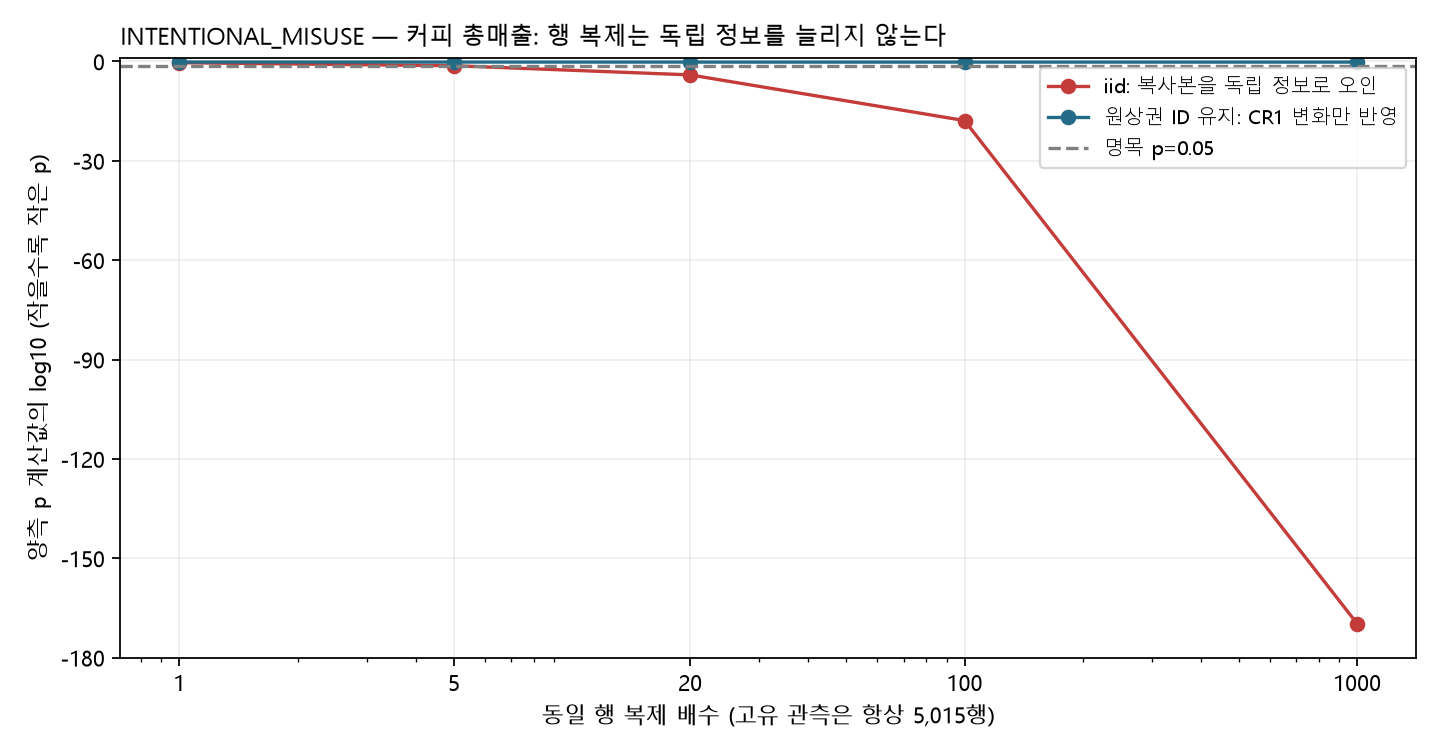

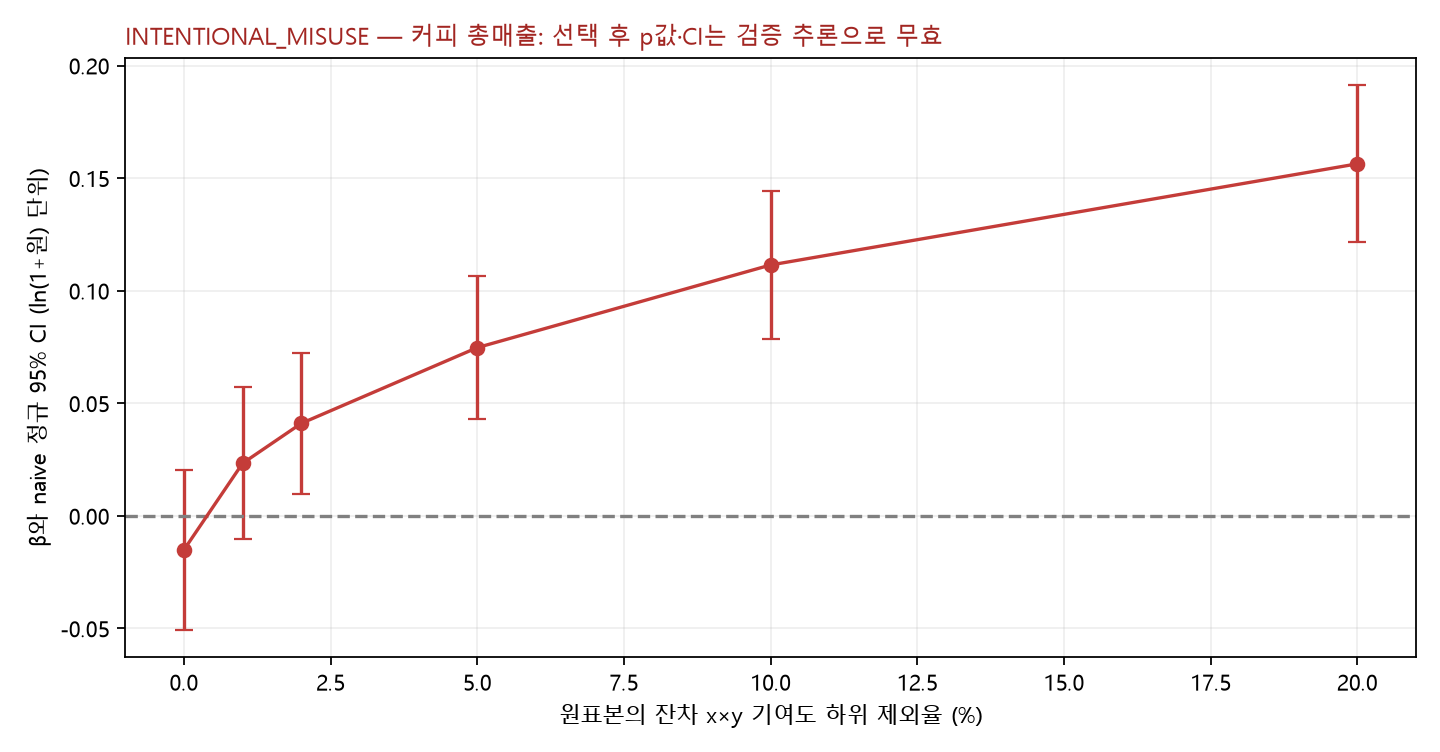

In [8]:
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import Image
plt.rcParams['font.family']='Malgun Gothic'; plt.rcParams['axes.unicode_minus']=False
fixed=ledger.loc[ledger.experiment.eq('B') & ledger.industry_id.eq(TRIM_INDUSTRY) & ledger.outcome.eq(TRIM_OUTCOME)]
fig,ax=plt.subplots(figsize=(9,4.7))
for method,label,color in [('replicated_TWFE_iid','iid: 복사본을 독립 정보로 오인','#c43c39'),('replicated_TWFE_original_cluster','원상권 ID 유지: CR1 변화만 반영','#246b87')]:
    d=fixed.loc[fixed.model.eq(method)].sort_values('replication_factor')
    ax.plot(d.replication_factor,d.log10_p,'o-',label=label,color=color)
ax.axhline(np.log10(.05),color='gray',ls='--',label='명목 p=0.05'); ax.set_xscale('log'); ax.set_ylim(-180,1); ax.set_yticks([-180,-150,-120,-90,-60,-30,0])
ax.set_xticks(REPLICATION_FACTORS,labels=REPLICATION_FACTORS); ax.set_xlabel('동일 행 복제 배수 (고유 관측은 항상 5,015행)')
ax.set_ylabel('양측 p 계산값의 log10 (작을수록 작은 p)'); ax.set_title('INTENTIONAL_MISUSE — 커피 총매출: 행 복제는 독립 정보를 늘리지 않는다',loc='left',fontsize=11)
ax.legend(fontsize=9); ax.grid(alpha=.2); fig.tight_layout(); fig.savefig(OUT/'02_replication_demo.png',dpi=160); plt.close(fig)
ct=ledger.loc[ledger.experiment.eq('C') & ledger.status.eq('estimated')].sort_values('trim_fraction')
fig,ax=plt.subplots(figsize=(9,4.7)); ax.errorbar(100*ct.trim_fraction,ct.coefficient,
    yerr=np.array([ct.coefficient-ct.ci_low,ct.ci_high-ct.coefficient]),fmt='o-',capsize=4,color='#c43c39')
ax.axhline(0,color='gray',ls='--'); ax.set_xlabel('원표본의 잔차 x×y 기여도 하위 제외율 (%)')
ax.set_ylabel('β와 naive 정규 95% CI (ln(1+원) 단위)')
ax.set_title('INTENTIONAL_MISUSE — 커피 총매출: 선택 후 p값·CI는 검증 추론으로 무효',loc='left',color='#a22622',fontsize=11)
ax.grid(alpha=.2); fig.tight_layout(); fig.savefig(OUT/'02_trim_demo.png',dpi=160); plt.close(fig)
display(Image(filename=str(OUT/'02_replication_demo.png')))
display(Image(filename=str(OUT/'02_trim_demo.png')))


## 저장·불변성 확인 및 해석 범위

전수 결과를 `02_results.csv`, 각 단계 선택 내역을 `02_trim_selection.csv`, 점검 결과를 `02_implementation_checks.csv`에 저장한다. 행 복제와 결과 기반 제외에서 작은 p값이 나오더라도 본 연구의 효과가 입증된 것이 아니다. A의 FE 제거 결과는 다른 연관성을 추정한다. 올바른 개선은 실제 날짜·시간·공연 개최와 매출의 측정, 적절한 대조군과 독립 정보 확충, 자료와 설계에 맞는 추론에 달려 있다. 이 노트북의 복제·군집 무시·결과 선택은 개선으로 추천하지 않는다.

통상적인 사후 검정력은 계산하지 않는다. 여러 시도 중 유의한 것만 선별해 보고하지 않으며 기존 본 연구 결과·원자료의 보호 해시를 실행 전후 대조한다.

In [9]:
ledger.to_csv(OUT/'02_results.csv',index=False,encoding='utf-8-sig')
counts.to_csv(OUT/'02_counts.csv',index=False,encoding='utf-8-sig')
trim_selection.to_csv(OUT/'02_trim_selection.csv',index=False,encoding='utf-8-sig')
pd.DataFrame(checks).to_csv(OUT/'02_implementation_checks.csv',index=False,encoding='utf-8-sig')
unchanged={p:sha(ROOT/p)==h for p,h in PROTECTED.items()}
assert all(unchanged.values()),[p for p,v in unchanged.items() if not v]
check_frame=pd.DataFrame(checks); assert check_frame.passed.all()
summary={
 'status':'complete','created_at_utc':datetime.now(timezone.utc).isoformat(),'exploratory':True,'confirmatory':False,
 'prior_results_seen':True,'for_research_use':False,'causal_interpretation_allowed':False,'raw_data_mutated':False,
 'network_requests':0,'all_inputs_unchanged':all(unchanged.values()),'protected_file_count':len(PROTECTED),
 'validation_all_passed':bool(check_frame.passed.all()),'sample_key_sha256':SAMPLE_HASH,'unique_rows':len(frame),
 'unique_areas':int(frame.area_id.nunique()),'outcomes':OUTCOMES,'replication_factors':REPLICATION_FACTORS,
 'trim_target_preselected':{'industry_id':TRIM_INDUSTRY,'industry':INDUSTRY_NAMES[TRIM_INDUSTRY],'outcome':TRIM_OUTCOME,
                          'fractions':TRIM_FRACTIONS,'direction':'remove smallest original TWFE residual x*y once; favor positive beta',
                          'post_selection_p_and_ci_valid':False,'minimum_two_quarters_and_twenty_clusters_maintained':True},
 'attempt_counts':ledger.groupby('experiment').size().to_dict(),'estimated_counts':ledger.groupby('experiment').status.apply(lambda s:int(s.eq('estimated').sum())).to_dict(),
 'all_attempts_recorded':True,'unplanned_model_search':False,'expected_attempts':286,'actual_attempts':len(ledger),
 'nominal_p_counts_not_evidence_of_valid_effect':json.loads(counts.to_json(orient='records')),
 'important_interpretation':[
  'TWFE cluster reference estimates conditional quarterly within-area associations, not causal audience spending.',
  'Quarter-only and pooled cluster models include between-area variation and change the descriptive estimand.',
  'iid uses joint homoskedastic RSS/(N-K), ignoring serial dependence and heteroskedasticity.',
  'Duplicate rows add no independent information. Original-cluster uncorrected covariance is invariant; CR1 covariance changes.',
  'Outcome-dependent trimming uses y for selection, so naive normal p and CI are invalid after selection.',
  'Doubling contrast concerns 1+exposure and geometric mean of 1+sales, not arithmetic sales growth.',
  'All methods and attempts are disclosed; no result is recommended as a research improvement.'
 ],'p_numeric_floor':1e-300,'p_floor_display':'<1e-300','p_floor_count':int(ledger.p_is_numeric_floor.fillna(False).sum()),
 'maximum_check_error':float(check_frame.max_abs_error.max()),
 'source_notebook':'test/notebooks/02_유의성부풀리기_시연.ipynb','lab_plan_sha256':PROTECTED['test/metadata/lab_plan.json'],
 'environment':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__},
 'outputs':{p.relative_to(ROOT).as_posix():{'sha256':sha(p),'bytes':p.stat().st_size} for p in sorted(OUT.glob('02_*')) if p.name!='02_summary.json'}
}
(OUT/'02_summary.json').write_text(json.dumps(summary,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8')
display(Markdown(f"**실행 완료:** {len(ledger)}개 계산을 전수 저장했다. 보호 입력 {len(PROTECTED)}개가 모두 불변이다. 명목 p<0.05 결과는 오용·선택·추정 대상 변경의 맥락에서만 읽어야 한다."))
display(counts)


**실행 완료:** 286개 계산을 전수 저장했다. 보호 입력 306개가 모두 불변이다. 명목 p<0.05 결과는 오용·선택·추정 대상 변경의 맥락에서만 읽어야 한다.

,experiment,model,outcome,replication_factor,trim_fraction,attempts,estimated,nominal_p_below_05,minimum_p
0,A,TWFE_cluster,log1p_night_sales_21_24_won,1,0.00,10,10,0,1.942316e-01
1,A,TWFE_cluster,log1p_total_sales_won,1,0.00,10,10,0,1.308222e-01
2,A,TWFE_iid,log1p_night_sales_21_24_won,1,0.00,10,10,0,2.559580e-01
3,A,TWFE_iid,log1p_total_sales_won,1,0.00,10,10,2,7.218998e-03
4,A,pooled_cluster,log1p_night_sales_21_24_won,1,0.00,10,10,4,7.589654e-03
...,...,...,...,...,...,...,...,...,...
29,C,outcome_selected_TWFE_iid_normal,log1p_total_sales_won,1,0.01,1,1,0,1.766899e-01
30,C,outcome_selected_TWFE_iid_normal,log1p_total_sales_won,1,0.02,1,1,1,1.012815e-02
31,C,outcome_selected_TWFE_iid_normal,log1p_total_sales_won,1,0.05,1,1,1,3.685458e-06
32,C,outcome_selected_TWFE_iid_normal,log1p_total_sales_won,1,0.10,1,1,1,3.082614e-11
